In [ ]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load the dataset
df_metro = pd.read_csv("/content/sample_data/all_features_traffic_dataset.csv")

print(" Dataset loaded successfully")
print(f"Shape: {df_metro.shape}")
print(f"\nFirst 5 rows:")
print(df_metro.head())

 Dataset loaded successfully
Shape: (61368, 30)

First 5 rows:
             Timestamp  Traffic_Volume  Traffic_Speed  Traffic_Density  \
0  2018-01-01 00:00:00             910      52.332534               30   
1  2018-01-01 01:00:00            3822      74.016548               30   
2  2018-01-01 02:00:00            3142      47.194336               30   
3  2018-01-01 03:00:00             516      57.084061               70   
4  2018-01-01 04:00:00            4476      54.168042               30   

   Time_of_Day  Day_of_Week Weather_Conditions  Road_Segment_ID  Road_Length  \
0            0            0              Clear               79     8.545500   
1            1            0              Clear                6     6.867493   
2            2            0              Clear              305     7.792069   
3            3            0              Clear               19     6.655005   
4            4            0              Clear              358     7.284540   

   Number_o

In [ ]:
print("\n" + "="*50)
print("COLUMN INFORMATION")
print("="*50)
print(df_metro.info())

print("\n" + "="*50)
print("FIRST 10 COLUMN NAMES")
print("="*50)
print(df_metro.columns[:10].tolist())


COLUMN INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 61368 entries, 0 to 61367
Data columns (total 30 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Timestamp                  61368 non-null  object 
 1   Traffic_Volume             61368 non-null  int64  
 2   Traffic_Speed              61368 non-null  float64
 3   Traffic_Density            61368 non-null  int64  
 4   Time_of_Day                61368 non-null  int64  
 5   Day_of_Week                61368 non-null  int64  
 6   Weather_Conditions         61368 non-null  object 
 7   Road_Segment_ID            61368 non-null  int64  
 8   Road_Length                61368 non-null  float64
 9   Number_of_Lanes            61368 non-null  int64  
 10  Intersection_Info          61368 non-null  int64  
 11  Traffic_Signals            61368 non-null  int64  
 12  Proximity_to_POI           61368 non-null  float64
 13  Adjacency_Matrix          

In [ ]:
# Look for columns that might represent congestion
possible_targets = [col for col in df_metro.columns if 'congest' in col.lower() or
                    'delay' in col.lower() or 'level' in col.lower()]
print("\n Possible target columns:", possible_targets)

# If 'Congestion_Level' exists, use it. Otherwise, create a simple rule.
if 'Congestion_Level' in df_metro.columns:
    y = df_metro['Congestion_Level']
    print("\n Using existing 'Congestion_Level' column")
else:
    # Create congestion level from volume & speed (example rule)
    # Low: Traffic_Volume < 50, Moderate: 50–100, High: 100–150, Severe: >150
    bins = [0, 50, 100, 150, np.inf]
    labels = [0, 1, 2, 3]
    df_metro['Congestion_Level'] = pd.cut(df_metro['Traffic_Volume'], bins=bins, labels=labels)
    y = df_metro['Congestion_Level']
    print("\n Created 'Congestion_Level' from 'Traffic_Volume' column")


 Possible target columns: ['Congestion_Level', 'Delay_Reduction', 'Emission_Levels']

 Using existing 'Congestion_Level' column


In [ ]:
# Choose available numeric columns
numeric_cols = df_metro.select_dtypes(include=[np.number]).columns.tolist()

# Remove the target from features
if 'congestion_level' in numeric_cols:
    numeric_cols.remove('congestion_level')

# Use first 10 numeric columns as features (or all if you want)
feature_cols = numeric_cols[:10]  # adjust as needed
X = df_metro[feature_cols]

# Drop rows with missing values
X = X.dropna()
y = y.loc[X.index]

print(f"\n Features selected: {feature_cols}")
print(f"Final X shape: {X.shape}")
print(f"Final y shape: {y.shape}")


 Features selected: ['Traffic_Volume', 'Traffic_Speed', 'Traffic_Density', 'Time_of_Day', 'Day_of_Week', 'Road_Segment_ID', 'Road_Length', 'Number_of_Lanes', 'Intersection_Info', 'Traffic_Signals']
Final X shape: (61368, 10)
Final y shape: (61368,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\nTraining samples: {X_train.shape[0]}")
print(f"Test samples: {X_test.shape[0]}")


Training samples: 49094
Test samples: 12274


In [ ]:
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)


MODEL PERFORMANCE (Metropolitan Dataset)
 Accuracy: 0.4003 (40.03%)

Classification Report:
              precision    recall  f1-score   support

        High       0.14      0.01      0.02      2476
         Low       0.40      0.51      0.45      4886
      Medium       0.40      0.49      0.44      4912

    accuracy                           0.40     12274
   macro avg       0.32      0.34      0.30     12274
weighted avg       0.35      0.40      0.36     12274



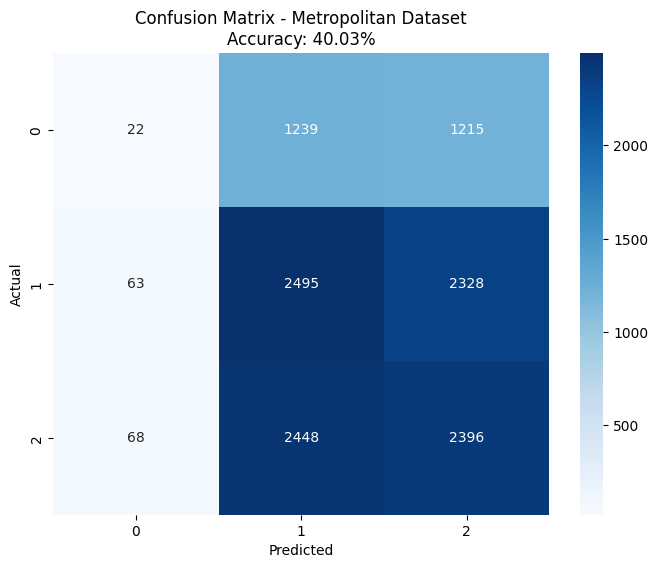

In [ ]:
accuracy = accuracy_score(y_test, y_pred)
print("\n" + "="*50)
print("MODEL PERFORMANCE (Metropolitan Dataset)")
print("="*50)
print(f" Accuracy: {accuracy:.4f} ({accuracy*100:.2f}%)")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title(f'Confusion Matrix - Metropolitan Dataset\nAccuracy: {accuracy:.2%}')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

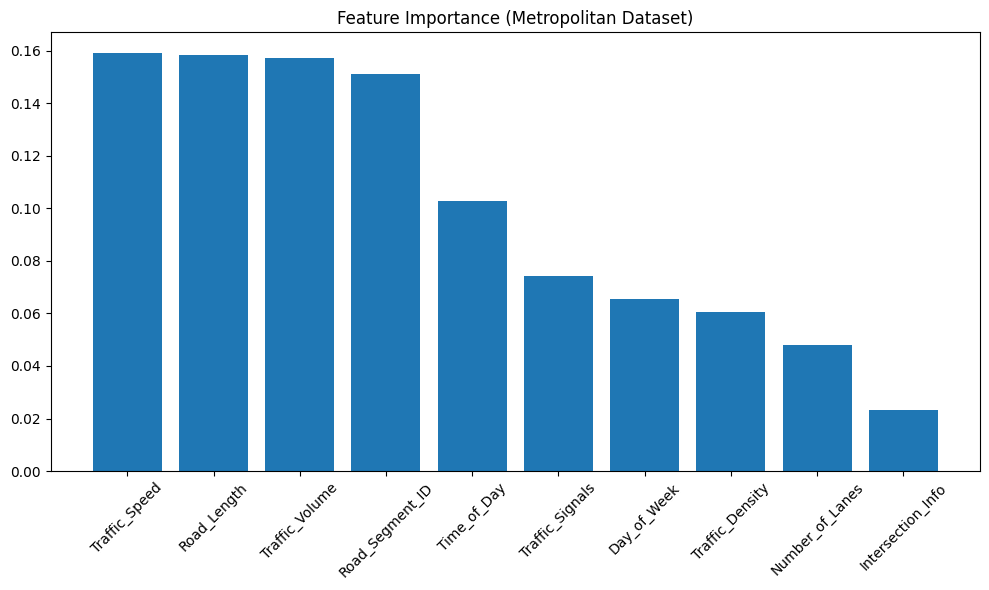

In [ ]:
importances = model.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(10,6))
plt.title('Feature Importance (Metropolitan Dataset)')
plt.bar(range(len(importances[:10])), importances[indices[:10]])
plt.xticks(range(len(importances[:10])), [feature_cols[i] for i in indices[:10]], rotation=45)
plt.tight_layout()
plt.show()